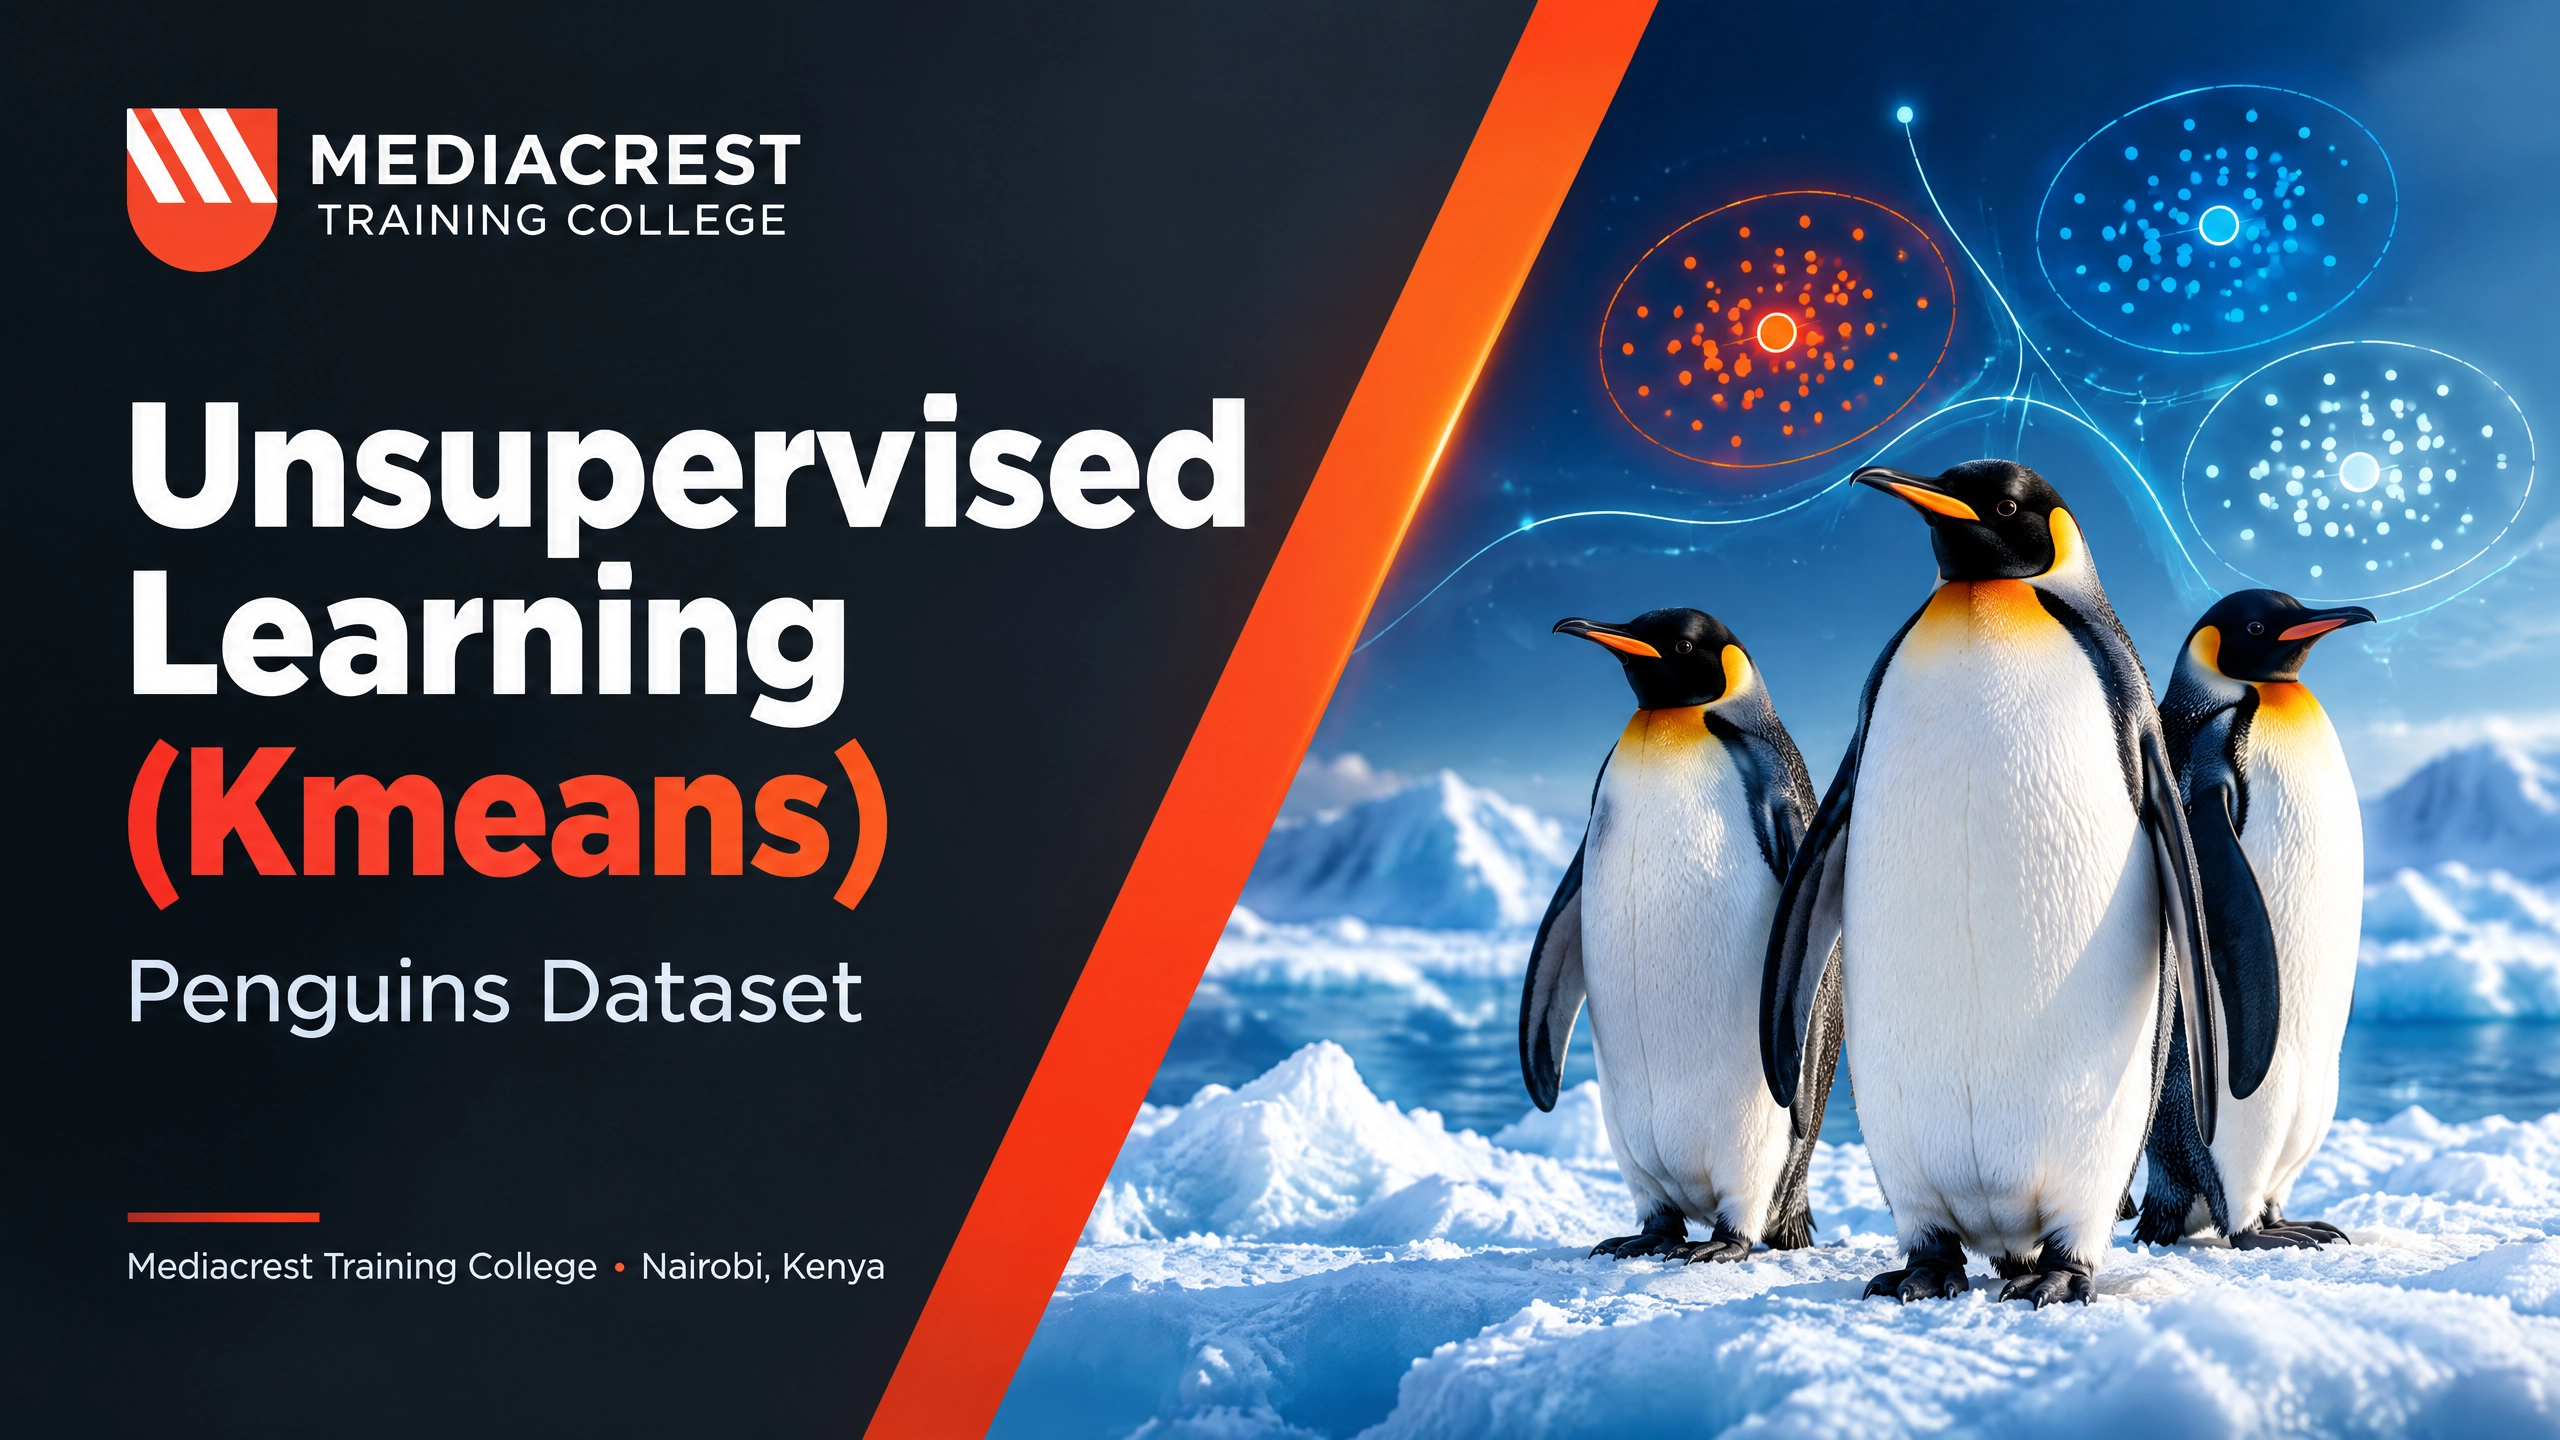

### **UNSUPERVISED LEARNING**
Unsupervised learning is primarily concerned clustering of data points that have similar characteristic. There are quite a number of clustering algorithms including but not limited to;

* KMeans Clustering
* Hierarchical Clustering
* DBSCAN Clustering etc. 

Unsupervised is also concerned with dimensionality reduction. This technique is common especially in reducing data with many variables into manageable dataset. The commonly used technique for dimensionality is Principle Component Analysis (PCA)

### **CLUSTERING**
Clustering is the techniques of putting together data points that have similar characteristic together into what we call clusters. 

#### **KMEANS CLUSTERING**
K-Means of the simplest and one of the most commonly used algorithms for clustering. This technique operates the three universal assumptions that:

* Clusters are spherical
* Clusters are well-separated
* Clusters are roughly of equal size

The process begins by selecting the number of clusters, k, which must be specified in advance. Initial centroids are chosen either randomly or using a more strategic method such as `K-Means++`. Each data point is then assigned to the nearest centroid based on `Euclidean distance`. After all points are assigned, the centroids are updated to the mean of the points in each cluster. This assignment and updated cycle repeats iteratively until the centroids stabilize, meaning that further iterations do not result in significant changes in cluster membership.

One of the strengths of K-Means lies in its computational efficiency and scalability, making it suitable for large datasets. It is often used in applications such as customer segmentation, image compression, and document clustering. 

However, its performance depends heavily on the choice of `k`. To determine the optimal number of clusters, practitioners and data analysts commonly use the `elbow method`, which involves plotting `With Clusters Sum of Squares` WCSS against different values of k and identifying the point where the rate of decrease sharply slows—a visual "elbow." Alternatively, the silhouette score, which measures how tightly grouped data points are within clusters compared to other clusters, can provide a more quantitative assessment.

Despite its popularity, K-Means has notable limitations. 
* It is sensitive to the initial placement of centroids, which can lead to convergence on suboptimal solutions. Multiple random restarts (controlled by the n_init parameter in implementations) help mitigate this issue. 
* Additionally, K-Means struggles with clusters that are not convex or spherical in shape, and it is easily influenced by outliers due to its reliance on mean-based centroids. It also assumes that all clusters are of similar size, which may not reflect real-world data distributions.


#### **Install Needed Libraries for K-Means Clustering**

In [ ]:
#!pip install umap-learn
#!pip install scipy
#!pip install fpgrowth-py

#### **Import the Needed Libraries**

#### **Primary Function Libraries**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### **Machine Learning Libraries**

In [4]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, 
                             davies_bouldin_score, 
                             adjusted_rand_score,
                             normalized_mutual_info_score,
                             calinski_harabasz_score,
                             homogeneity_score
    
)

##### **Dimensionality Reduction Libraries**

In [6]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import (
    dendrogram, linkage, cut_tree
)
import umap

##### **Filter Warnings**

In [7]:
import warnings
warnings.filterwarnings('ignore')

#### **Association Rule Related Libraries**

In [10]:
from fpgrowth_py import fpgrowth
import itertools

#### **Libraries for Setting the Visualization Themes**

In [11]:
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

### **Load PalmerPenguins Dataset**

In [13]:
df = pd.read_csv("penguins.csv")
df.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007


#### **Quick Overview of the Dataset**

In [17]:
print("=" * 110)
print("DATASET OVERVIEW")
print("=" * 110)
print(f"\nShape: {df.shape}")

DATASET OVERVIEW

Shape: (344, 8)


##### **Check the Variable Names in the Dataset**

In [19]:
print("=" * 110)
print("DATASET OVERVIEW")
print("=" * 110)
print(f"\nColumn Name: {df.columns.tolist()}")

DATASET OVERVIEW

Column Name: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


#### **Check the `DataTypes` and the `Number of Observations`**

In [20]:
print("=" * 110)
print("DATASET OVERVIEW")
print("=" * 110)
print(f"\nColumn Name: {df.info()}")

DATASET OVERVIEW
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB

Column Name: None


#### **Check the Number of Missing Values**

In [21]:
print("=" * 110)
print("MISSING VALUES")
print("=" * 110)
print(f"\nMissing Values per Variable: \n{df.isnull().sum()}")

MISSING VALUES

Missing Values per Variable: 
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


#### **Check the Percentage of Missing Values**

In [24]:
print("=" * 110)
print("MISSING VALUES")
print("=" * 110)
print(f"\nPercentage Missing Values per Variable: \n{(df.isnull().sum()/len(df)*100).round(3)}")

MISSING VALUES

Percentage Missing Values per Variable: 
species              0.000
island               0.000
bill_length_mm       0.581
bill_depth_mm        0.581
flipper_length_mm    0.581
body_mass_g          0.581
sex                  3.198
year                 0.000
dtype: float64


#### **Check the Number of `Penguin Species`**

In [25]:
print("=" * 110)
print("SPECIES DISTRIBUTION")
print("=" * 110)
print(f"\nSpecies Distribution: {df['species'].value_counts()}")

SPECIES DISTRIBUTION

Species Distribution: species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


### **Data Preprocessing**

In [26]:
df_clean = df.copy()
df_clean.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


#### **Drop the Missing Values**

In [27]:
df_clean = df_clean.dropna()
print(f"\nRows After Deletion of Missing Values: {len(df_clean)}")


Rows After Deletion of Missing Values: 333


In [28]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
 7   year               333 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 23.4+ KB


#### **Select Numerical Features for Clustering**

In [29]:
numerical_features = ['bill_length_mm', 'bill_depth_mm',
                      'flipper_length_mm', 'body_mass_g']
numerical_features

['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

#### **Extract the Values for Numerical Features**

In [33]:
X = df_clean[numerical_features].values
X

array([[  39.1,   18.7,  181. , 3750. ],
       [  39.5,   17.4,  186. , 3800. ],
       [  40.3,   18. ,  195. , 3250. ],
       ...,
       [  49.6,   18.2,  193. , 3775. ],
       [  50.8,   19. ,  210. , 4100. ],
       [  50.2,   18.7,  198. , 3775. ]], shape=(333, 4))

#### **Create the `target` variable and Put aside**

In [34]:
y_true = df_clean['species'].values
y_true[:200]

array(['Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adel

#### **Check the Class Distribution for the Target Variable**

In [35]:
freq_true = pd.Series(y_true).value_counts()
freq_true

Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

#### **Encode the Values for the Target Variable**

In [36]:
le = LabelEncoder()
y_encoded = le.fit_transform(y_true)
y_encoded

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

#### **Check the Class Distribution for the Encoded Target Variable**

In [37]:
freq_true = pd.Series(y_encoded).value_counts()
freq_true

0    146
2    119
1     68
Name: count, dtype: int64

#### **Features Scaling**

In [38]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### **Summary Statistics for the Standardized Features**

In [39]:
print("\n" + "="*110)
print("SUMMARY STATISTICS FOR STANDARDIZED FEATURES")
print("\n" + "="*110)
print(f"Mean after Scaling: {X_scaled.mean(axis = 0).round(3)}")
print(f"Mean after Scaling: {X_scaled.std(axis = 0).round(3)}")


SUMMARY STATISTICS FOR STANDARDIZED FEATURES

Mean after Scaling: [-0. -0.  0. -0.]
Mean after Scaling: [1. 1. 1. 1.]


### **Determining the Number of Clusters *`k`* Needed**